# Growth Recursive — Neural Net

## Setup

[JAX](https://docs.jax.dev) underlies everything below: array math via
`jax.numpy`,
[compilation](https://docs.jax.dev/en/latest/jit-compilation.html) via
`jax.jit`, and exact derivatives via [automatic
differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
— the solver differentiates the residual program itself, so no
derivative is coded by hand. JAX defaults to 32-bit floats, so we switch
on 64-bit and the most accurate matmul *before* creating any array, then
import everything we need.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")

import math
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import nnx
from nlls_gram import LevenbergMarquardt
from tinydiffeq import RK4, ConstantStepSize, SaveAt, solve_bvp, solve_ode

Structural parameters: the sequential calibration plus balanced growth
at rate $g$. Technology is Hicks-neutral, $f(z, k) = z k^a$ with
$z(t) = z_0 e^{(1-a) g t}$, so the labor-augmenting index $z^{1/(1-a)}$
grows at $g$ and detrended quantities are stationary. The dict `p` is
the solver’s differentiable-parameter pytree —
[`nlls-gram`](https://pypi.org/project/nlls-gram/) differentiates the
solve implicitly with respect to every leaf. Training integrates from
$(z_0, k_0)$, so the initial condition is a leaf too.

In [2]:
a = 1.0 / 3.0  # capital share in f(z, k) = z k^a
delta = 0.1  # depreciation rate
rho_hat = -4.0 * math.log(0.9896)  # continuous discount rate (quarterly beta anchor)
sigma_crra = 2.0  # CRRA curvature
g = 0.02  # balanced growth rate; TFP z grows at (1 - a) g
z_0 = 1.0  # initial TFP
k_0 = 1.0  # initial capital
p = {
    "a": a,
    "delta": delta,
    "rho_hat": rho_hat,
    "sigma_crra": sigma_crra,
    "g": g,
    "z_0": z_0,
    "k_0": k_0,
}

Parameters of the algorithm: the network width, head scale and seed, the
simulation horizons and step counts, the Levenberg–Marquardt settings,
and the benchmark boundary-value solve.

In [3]:
WIDTH = 32
HEAD_INIT_SCALE = 1e-3  # near-zero head: the policy starts at the anchor
SEED = 0
TRAIN_T = 100.0
TRAIN_STEPS = 64  # RK4 steps; residuals sit on the 65 integrator states
TEST_T = 40.0
TEST_STEPS = 40
TVC_T = 200.0
TVC_STEPS = 256
MAX_STEPS = 250
LOSS_THRESHOLD = 1e-14  # sum of squared residuals; atol is its square root
INIT_DAMPING = 1e-8
BVP_T = 200.0
BVP_POINTS = 201
BVP_TOL = 1e-10
BVP_MAX_NODES = 2048

## The model

The recursive formulation works on the log state $x = (\log z, \log k)$
and seeks an investment *policy* $i(x)$ rather than a time path. Given a
policy, the state drifts as

$$
\frac{d \log z}{dt} = (1 - a)\, g,
\qquad
\frac{d \log k}{dt} = \frac{i(x)}{k} - \delta,
$$

with consumption from the resource constraint, $c(x) = z k^a - i(x)$.
Optimality is the Euler equation for consumption growth along the flow,

$$
\frac{d \log c}{dt} = \frac{1}{\sigma}\big(a\, z\, k^{a-1} - \delta - \hat\rho\big),
$$

where the left side is the directional derivative of $\log c(x)$ along
the state drift. On the balanced growth path capital and consumption
both grow at $g$ while detrended capital $\kappa = k\, z^{-1/(1-a)}$
converges to a steady state.

## The hypothesis class

The policy is *homothetic*: an MLP of the single detrended state
$\log \kappa = \log k - \log z/(1-a)$, whose output multiplies the
replacement-investment anchor $\delta k$ through the normalized softplus
$U$ (with $U(0) = U'(0) = 1$),

$$
i(x) = \delta\, k\; U\!\big(h_\theta(\log \kappa)\big),
$$

so a near-zero head initializes at exact replacement investment
$i = \delta k$, and the trend is absorbed by construction. The
structural constants $a$ and $\delta$ are baked into the map, which
makes the policy a function of the state alone.

In [4]:
def unit_softplus(raw):
    return jax.nn.softplus(2.0 * jnp.log(2.0) * raw) / jnp.log(2.0)


class InvestmentPolicy(nnx.Module):
    def __init__(self, *, rngs: nnx.Rngs):
        self.l1 = nnx.Linear(1, WIDTH, param_dtype=jnp.float64, rngs=rngs)
        self.l2 = nnx.Linear(WIDTH, WIDTH, param_dtype=jnp.float64, rngs=rngs)
        self.l3 = nnx.Linear(WIDTH, WIDTH, param_dtype=jnp.float64, rngs=rngs)
        self.head = nnx.Linear(
            WIDTH,
            1,
            kernel_init=nnx.initializers.normal(HEAD_INIT_SCALE),
            param_dtype=jnp.float64,
            rngs=rngs,
        )

    def __call__(self, log_state):
        log_z, log_k = log_state
        h = jnp.atleast_1d(log_k - log_z / (1.0 - a))
        h = jax.nn.gelu(self.l1(h))
        h = jax.nn.gelu(self.l2(h))
        h = jax.nn.gelu(self.l3(h))
        return delta * jnp.exp(log_k) * unit_softplus(self.head(h))

## Model functions and simulation

Consumption clears the resource constraint, the drift is the model’s law
of motion under the policy, and the Euler residual takes $d \log c / dt$
as a forward-mode
[`jax.jvp`](https://docs.jax.dev/en/latest/automatic-differentiation.html)
of $\log c(x)$ along that drift. Closed-loop trajectories come from
[`tinydiffeq`](https://github.com/HighDimensionalEconLab/tinydiffeq)’s
fixed-step RK4 `solve_ode`, saving the integrator’s own states; the
policy is closed over, so training differentiates straight through the
simulation.

In [5]:
def consumption(policy, log_state, p):
    z, k = jnp.exp(log_state)
    return z * k ** p["a"] - policy(log_state)[0]


def log_state_drift(policy, log_state, p):
    log_k = log_state[1]
    return jnp.stack(
        [(1.0 - p["a"]) * p["g"], policy(log_state)[0] / jnp.exp(log_k) - p["delta"]]
    )


def euler_residual(policy, log_state, p):
    drift = log_state_drift(policy, log_state, p)
    log_c, dlog_c_dt = jax.jvp(
        lambda state: jnp.log(consumption(policy, state, p)), (log_state,), (drift,)
    )
    z, k = jnp.exp(log_state)
    # 0 * log_c is NaN where c <= 0; the tangent alone would stay finite there.
    return (
        dlog_c_dt
        + 0.0 * log_c
        - (p["a"] * z * k ** (p["a"] - 1.0) - p["delta"] - p["rho_hat"])
        / p["sigma_crra"]
    )


def simulate(policy, initial_log_state, T, n_steps, p):
    return solve_ode(
        lambda log_state: log_state_drift(policy, log_state, p),
        RK4(),
        0.0,
        T,
        initial_log_state,
        dt_0=T / n_steps,
        controller=ConstantStepSize(),
        max_steps=n_steps,
        save_at=SaveAt(steps=True),
    )

## The least-squares problem and solve

Training is closed-loop: the current policy is rolled out from
$(z_0, k_0)$ and the Euler residual is enforced at the integrator’s own
states — nothing is interpolated inside the residual,

$$
\min_\theta\ \frac{1}{n} \sum_{j} \Big(
\frac{d \log c}{dt}\Big|_{x_j(\theta)} - \frac{1}{\sigma}\big(a z_j k_j^{a-1} - \delta - \hat\rho\big)
\Big)^2,
$$

so the collocation states move with $\theta$. The initial state is
computed from `p` inside the residual, keeping the solution
differentiable in the initial condition. A single seed reaches the loss
threshold here; a production run wraps the same solve in a multi-start
over several draws.

In [6]:
graphdef, theta_0 = nnx.split(InvestmentPolicy(rngs=nnx.Rngs(SEED)), nnx.Param)


def residual_fn(theta, args, p):
    policy = nnx.merge(args["graphdef"], theta)
    initial_log_state = jnp.log(jnp.array([p["z_0"], p["k_0"]]))
    solution = simulate(policy, initial_log_state, TRAIN_T, TRAIN_STEPS, p)
    euler = jax.vmap(lambda s: euler_residual(policy, s, p))(solution.xs)
    # A trajectory that never reached TRAIN_T is a loud optimizer failure
    # rather than a fit to its finite prefix.
    return jnp.where(solution.ok, euler / jnp.sqrt(euler.size), jnp.inf)


solver = LevenbergMarquardt(residual_fn, init_damping=INIT_DAMPING)
start = time.perf_counter()
result = solver.solve(
    theta_0,
    {"graphdef": graphdef},
    p=p,
    max_steps=MAX_STEPS,
    atol=math.sqrt(LOSS_THRESHOLD),
    max_steps_is_success=False,
)
solve_time = time.perf_counter() - start
policy = nnx.merge(graphdef, result.x)

## Benchmark reference

Accuracy is measured against the exact saddle path, solved as a
boundary-value problem in the detrended coordinates
$\kappa = k\, z^{-1/(1-a)}$, $\tilde c = c\, z^{-1/(1-a)}$,

$$
\kappa' = \kappa^a - \tilde c - (\delta + g)\, \kappa,
\qquad
\tilde c' = \frac{\tilde c}{\sigma}\big(a \kappa^{a-1} - \hat\rho - \delta - \sigma g\big),
$$

with $\kappa(0) = \kappa_0$, the terminal pin $\kappa(T) = \kappa_{ss}$,
and an initial guess that approaches the steady state at the linearized
stable eigenvalue, solved by
[`tinydiffeq`](https://github.com/HighDimensionalEconLab/tinydiffeq)’s
`solve_bvp` (a JAX port of scipy’s collocation method). None of this
enters the residual or the initialization — the closed-loop training
above never sees it.

In [7]:
kappa_0 = k_0 / z_0 ** (1.0 / (1.0 - a))
kappa_ss = ((delta + rho_hat + sigma_crra * g) / a) ** (1.0 / (a - 1.0))


def kappa_field(_, y):
    kappa, c_tilde = y
    return jnp.array(
        [
            kappa**a - c_tilde - (delta + g) * kappa,
            (c_tilde / sigma_crra)
            * (a * kappa ** (a - 1.0) - rho_hat - delta - sigma_crra * g),
        ]
    )


def kappa_bc(ya, yb):
    return jnp.array([ya[0] - kappa_0, yb[0] - kappa_ss])


mesh = jnp.linspace(0.0, BVP_T, BVP_POINTS)
c_tilde_ss = kappa_ss**a - (delta + g) * kappa_ss
f_pp = a * (a - 1.0) * kappa_ss ** (a - 2.0)
trace = rho_hat + (sigma_crra - 1.0) * g
lambda_stable = 0.5 * (
    trace - jnp.sqrt(trace**2 - 4.0 * c_tilde_ss * f_pp / sigma_crra)
)
kappa_guess = kappa_ss + (kappa_0 - kappa_ss) * jnp.exp(lambda_stable * mesh)
y_guess = jnp.stack([kappa_guess, kappa_guess**a - (delta + g) * kappa_guess], axis=-1)
benchmark = solve_bvp(
    kappa_field, kappa_bc, mesh, y_guess, tol=BVP_TOL, max_nodes=BVP_MAX_NODES
)

## Results

The test rolls the trained policy from the same initial condition over a
fresh horizon and step size, evaluates the Euler residual along it, and
compares capital and consumption against the benchmark re-trended to
levels, $k^\star(t) = z_0^{1/(1-a)} e^{g t} \kappa(t)$. The
transversality certificate simulates to $T = 200$ and evaluates the log
of $e^{-\hat\rho T} c(T)^{-\sigma} k(T)$, normalized by its initial-date
value: far negative on the saddle path, positive on a capital bubble.

In [8]:
initial_log_state = jnp.log(jnp.array([z_0, k_0]))
test_solution = simulate(policy, initial_log_state, TEST_T, TEST_STEPS, p)
euler_test = jax.vmap(lambda s: euler_residual(policy, s, p))(test_solution.xs)
z_test, k_test = jnp.exp(test_solution.xs).T
c_test = jax.vmap(lambda s: consumption(policy, s, p))(test_solution.xs)

scale_test = z_0 ** (1.0 / (1.0 - a)) * jnp.exp(g * test_solution.ts)
kappa_benchmark, c_tilde_benchmark = benchmark(test_solution.ts).T
k_error = jnp.abs(k_test - scale_test * kappa_benchmark) / (
    scale_test * kappa_benchmark
)
c_error = jnp.abs(c_test - scale_test * c_tilde_benchmark) / (
    scale_test * c_tilde_benchmark
)

# Log transversality certificate at T, normalized by its initial-date value:
# (-rho_hat T - sigma log c(T) + log k(T)) - (-sigma log c(0) + log k(0)).
tvc_solution = simulate(policy, initial_log_state, TVC_T, TVC_STEPS, p)
terminal_log_state = tvc_solution.xs[-1]
c_T = consumption(policy, terminal_log_state, p)
k_T = jnp.exp(terminal_log_state[1])
c_init = consumption(policy, initial_log_state, p)
log_tvc = (-rho_hat * TVC_T - sigma_crra * jnp.log(c_T) + jnp.log(k_T)) - (
    -sigma_crra * jnp.log(c_init) + jnp.log(k_0)
)

print(f"solve: {int(result.steps)} steps in {solve_time:.2f}s (incl. jit)")
print(f"final loss: {float(result.info.loss):.3e}")
print(f"mean |Euler residual| test roll: {float(jnp.abs(euler_test).mean()):.3e}")
print(
    f"mean relative error vs benchmark: k {float(k_error.mean()):.3e}, "
    f"c {float(c_error.mean()):.3e}"
)
print(f"log-TVC at t={TVC_T:.0f}: {float(log_tvc):.1f}   (should be << 0)")

solve: 41 steps in 2.71s (incl. jit)
final loss: 5.538e-15
mean |Euler residual| test roll: 5.125e-07
mean relative error vs benchmark: k 1.313e-06, c 9.135e-07
log-TVC at t=200: -12.3   (should be << 0)

Detrended capital $\kappa = k\, z^{-1/(1-a)}$ tracks the benchmark
(dashed) up toward the balanced-growth steady state $\kappa_{ss}$ along
the test roll, and the Euler residual sits on zero.

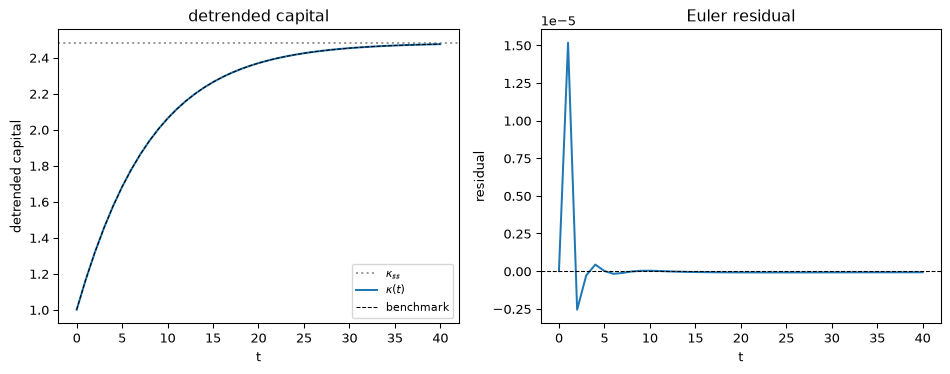

In [9]:
kappa_test = k_test / z_test ** (1.0 / (1.0 - a))

fig, (ax_k, ax_r) = plt.subplots(1, 2, figsize=(10, 4))
ax_k.axhline(float(kappa_ss), color="0.6", linestyle=":", label=r"$\kappa_{ss}$")
ax_k.plot(test_solution.ts, kappa_test, "C0", label=r"$\kappa(t)$")
ax_k.plot(test_solution.ts, kappa_benchmark, "k--", linewidth=0.8, label="benchmark")
ax_k.set(xlabel="t", ylabel="detrended capital", title="detrended capital")
ax_k.legend(fontsize=8)
ax_r.plot(test_solution.ts, euler_test, "C0")
ax_r.axhline(0.0, color="k", linestyle="--", linewidth=0.8)
ax_r.set(xlabel="t", ylabel="residual", title="Euler residual")
fig.tight_layout()
plt.show()